# Evaluasi tekanan darah TriaGo

Stage 1 memuat segmen dari berkas sumber PulseDB v2.0 dan memeriksa kualitas input. Hasil disimpan di memori untuk stage berikutnya.

## 1. Sumber data

PulseDB v2.0 menyediakan segmen ECG dan PPG yang sudah difilter dan dinormalisasi dalam kolom `ECG_F` dan `PPG_F`. Setiap segmen berisi 1.250 sampel pada 125 Hz (10 detik). `SegSBP` dan `SegDBP` adalah rerata nilai sistolik dan diastolik antar-denyut dari tekanan darah arteri (ABP) pada segmen yang sama. `T` menyimpan waktu sampel dalam rekaman.

Pilih folder lokal yang berisi `PulseDB_Vital` dan `PulseDB_MIMIC`. Seperti `extract_pulsedb.py` pada eksperimen GEMASTIK, pilih 25 file VitalDB dan 15 file MIMIC pertama berdasarkan nama file. Folder default berasal dari shortcut Google Drive PulseDB_v2_0.lnk yang dipilih pengguna. Google Drive dapat memuat berkas saat dibuka.

[Sumber format PulseDB v2.0](https://github.com/pulselabteam/PulseDB/blob/main/README.md) · [Artikel PulseDB, §2.2 dan §2.5](https://doi.org/10.3389/fdgth.2022.1090854)

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT_PULSEDB = Path('G:\\.shortcut-targets-by-id\\10mz4mfBo6NczPNbbjX0a9tAKQSMugBjV\\PulseDB_v2_0\\Segment_Files')
FS_PULSEDB = 125
SAMPEL_PER_SEGMEN = 1250
BATAS_SEGMEN = 150
KUOTA = {"PulseDB_Vital": 25, "PulseDB_MIMIC": 15}

if ROOT_PULSEDB is None:
    raise FileNotFoundError("Isi ROOT_PULSEDB dengan folder PulseDB v2.0 Segment_Files yang tersedia offline.")

inventaris = []
file_terpilih = []
for subset, kuota in KUOTA.items():
    folder = ROOT_PULSEDB / subset
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder subset tidak ditemukan: {folder}")
    files = sorted(folder.glob("*.mat"))
    inventaris.append({"Subset": subset, "File tersedia": len(files), "File dipilih": min(len(files), kuota)})
    if len(files) < kuota:
        raise ValueError(f"{subset}: tersedia {len(files)} file .mat, perlu {kuota} sesuai kohort acuan.")
    file_terpilih.extend((subset, file) for file in files[:kuota])

display(pd.DataFrame(inventaris).set_index("Subset"))

,File tersedia,File dipilih
Subset,,
PulseDB_Vital,2938,25
PulseDB_MIMIC,2423,15


## 2. Baca segmen dan audit kualitas data

Satu berkas mewakili satu subjek dalam subsetnya. Kunci grup memakai subset dan nama berkas secara internal. Kunci segmen memakai grup dan indeks kolom. Waktu awal yang berulang dalam satu berkas ditolak agar segmen yang sama tidak dihitung dua kali. Beberapa segmen dengan waktu berbeda dari subjek yang sama tetap sah.

Ikuti urutan penyaringan acuan: pilih `IncludeFlag = 1`, ambil paling banyak 150 segmen yang tersebar merata, lalu cek isi sinyal dan label. Batas acuan adalah SBP 70–200 mmHg, DBP 40–120 mmHg, dan SBP lebih tinggi dari DBP. Segmen dengan nilai hilang, waktu tak valid, atau sinyal tak lengkap dikeluarkan. Ini audit input. SQI tambahan dilakukan pada stage terpisah.

In [2]:
def baca_nilai(h5, grup, kolom, indeks):
    dataset = grup[kolom]
    if h5py.check_dtype(ref=dataset.dtype) is None:
        return np.asarray(dataset, dtype=float).ravel()
    referensi = dataset[0, indeks]
    if not referensi:
        return np.array([], dtype=float)
    return np.asarray(h5[referensi], dtype=float).ravel()

def baca_segmen(h5, subset, kode_subjek):
    if "Subj_Wins" not in h5:
        raise ValueError(f"{subset}: grup Subj_Wins tidak ditemukan.")

    grup = h5["Subj_Wins"]
    kolom_wajib = ("IncludeFlag", "ECG_F", "PPG_F", "SegSBP", "SegDBP", "T")
    hilang = [kolom for kolom in kolom_wajib if kolom not in grup]
    if hilang:
        raise ValueError(f"{subset}: kolom PulseDB v2.0 hilang: {hilang}")

    pakai_referensi = [h5py.check_dtype(ref=grup[kolom].dtype) is not None for kolom in kolom_wajib]
    if all(pakai_referensi):
        bentuk = grup["ECG_F"].shape
        if len(bentuk) != 2 or bentuk[0] != 1 or any(grup[kolom].shape != bentuk for kolom in kolom_wajib):
            raise ValueError(f"{subset}: tabel referensi segmen tidak sejajar.")
        jumlah_segmen = bentuk[1]
    elif not any(pakai_referensi) and all(grup[kolom].size == 1 for kolom in ("IncludeFlag", "SegSBP", "SegDBP")):
        # MATLAB dapat menyimpan satu segmen langsung sebagai array numerik.
        jumlah_segmen = 1
    else:
        raise ValueError(f"{subset}: format penyimpanan segmen tidak dikenali.")

    audit = {"Total segmen": jumlah_segmen, "Flag tidak valid": 0, "Flag ditolak": 0, "Di luar kuota": 0,
             "Sinyal tidak lengkap": 0, "Label kosong/tak hingga": 0, "Label di luar batas": 0,
             "Waktu tidak valid": 0, "Waktu berulang": 0, "Diterima": 0}
    kandidat = []
    for indeks in range(jumlah_segmen):
        flag = baca_nilai(h5, grup, "IncludeFlag", indeks)
        if flag.size != 1 or flag[0] not in (0, 1):
            audit["Flag tidak valid"] += 1
        elif flag[0] == 0:
            audit["Flag ditolak"] += 1
        else:
            kandidat.append(indeks)
    if len(kandidat) > BATAS_SEGMEN:
        audit["Di luar kuota"] = len(kandidat) - BATAS_SEGMEN
        posisi = np.linspace(0, len(kandidat) - 1, BATAS_SEGMEN, dtype=int)
        kandidat = [kandidat[i] for i in posisi]

    diterima = []
    awal_terpakai = set()
    for indeks in kandidat:
        ecg = baca_nilai(h5, grup, "ECG_F", indeks)
        ppg = baca_nilai(h5, grup, "PPG_F", indeks)
        if any(sinyal.size != SAMPEL_PER_SEGMEN or not np.isfinite(sinyal).all() for sinyal in (ecg, ppg)):
            audit["Sinyal tidak lengkap"] += 1
            continue

        sbp = baca_nilai(h5, grup, "SegSBP", indeks)
        dbp = baca_nilai(h5, grup, "SegDBP", indeks)
        if any(label.size != 1 or not np.isfinite(label).all() for label in (sbp, dbp)):
            audit["Label kosong/tak hingga"] += 1
            continue
        sbp, dbp = float(sbp[0]), float(dbp[0])
        if not (70 <= sbp <= 200 and 40 <= dbp <= 120 and sbp > dbp):
            audit["Label di luar batas"] += 1
            continue

        waktu = baca_nilai(h5, grup, "T", indeks)
        if (waktu.size != SAMPEL_PER_SEGMEN or not np.isfinite(waktu).all()
                or not np.allclose(np.diff(waktu), 1 / FS_PULSEDB, rtol=0, atol=0.001)):
            audit["Waktu tidak valid"] += 1
            continue
        awal = round(waktu[0] * FS_PULSEDB)
        if awal in awal_terpakai:
            audit["Waktu berulang"] += 1
            continue
        awal_terpakai.add(awal)
        diterima.append({
            "subset": subset, "grup": kode_subjek, "segmen": indeks,
            "waktu_awal_s": float(waktu[0]), "fs_hz": FS_PULSEDB,
            "ecg": ecg.astype(np.float32), "ppg": ppg.astype(np.float32),
            "sbp_mmhg": sbp, "dbp_mmhg": dbp,
        })

    audit["Diterima"] = len(diterima)
    assert sum(nilai for kunci, nilai in audit.items() if kunci != "Total segmen") == jumlah_segmen
    return diterima, audit

segmen_pulsedb = []
audit_file = []
for subset, file in file_terpilih:
    with h5py.File(file, "r") as h5:
        segmen, audit = baca_segmen(h5, subset, (subset, file.stem))
    segmen_pulsedb.extend(segmen)
    audit_file.append({"Subset": subset, **audit})

display(pd.DataFrame(audit_file).groupby("Subset").sum())
if not segmen_pulsedb:
    raise ValueError("Tidak ada segmen PulseDB yang lolos audit input.")
kunci_segmen = {(baris["grup"], baris["segmen"]) for baris in segmen_pulsedb}
assert len(kunci_segmen) == len(segmen_pulsedb)

,Total segmen,Flag tidak valid,Flag ditolak,Di luar kuota,Sinyal tidak lengkap,Label kosong/tak hingga,Label di luar batas,Waktu tidak valid,Waktu berulang,Diterima
Subset,,,,,,,,,,
PulseDB_MIMIC,30871,0,0,29261,0,0,1,0,6,1603
PulseDB_Vital,13978,0,0,10686,0,0,174,0,0,3118


## 3. Ringkas data dan lihat contoh

Tabel menampilkan jumlah subjek yang masih memiliki segmen setelah audit, serta total durasi segmen yang dipakai. Grafik memperlihatkan ECG dan PPG pada dua detik yang sama dengan sumbu waktu dalam detik. Tahap ini belum melakukan resampling, SQI tambahan, atau pelatihan.

,Subjek,Segmen,Laju_sampling_Hz,Durasi segmen (menit)
subset,,,,
PulseDB_MIMIC,15,1603,125,267.17
PulseDB_Vital,25,3118,125,519.67


,sbp_mmhg,dbp_mmhg
count,4721.00,4721.00
mean,118.73,64.39
std,18.47,12.32
min,70.05,40.09
25%,106.44,54.52
50%,117.97,62.82
75%,131.89,73.29
max,192.22,109.81


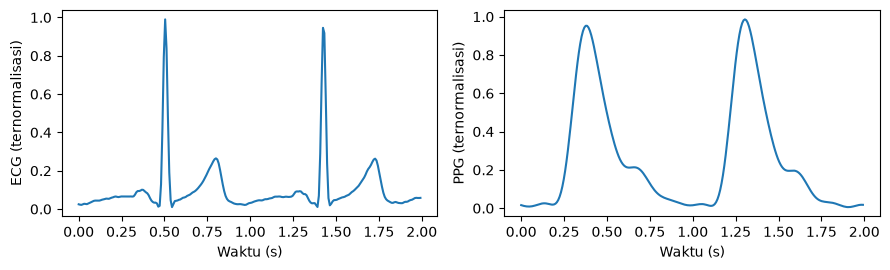

In [3]:
ringkasan = pd.DataFrame([
    {kolom: baris[kolom] for kolom in ("subset", "grup", "segmen", "fs_hz", "sbp_mmhg", "dbp_mmhg")}
    for baris in segmen_pulsedb
])
kohort = ringkasan.groupby("subset").agg(
    Subjek=("grup", "nunique"), Segmen=("segmen", "size"), Laju_sampling_Hz=("fs_hz", "first"),
)
kohort["Durasi segmen (menit)"] = kohort["Segmen"] * SAMPEL_PER_SEGMEN / FS_PULSEDB / 60
display(kohort.round(2))
display(ringkasan[["sbp_mmhg", "dbp_mmhg"]].describe().round(2))

contoh = segmen_pulsedb[0]
jumlah_sampel = 2 * FS_PULSEDB
waktu = np.arange(jumlah_sampel) / FS_PULSEDB
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharex=True)
for ax, kanal in zip(axes, ("ecg", "ppg")):
    ax.plot(waktu, contoh[kanal][:jumlah_sampel])
    ax.set(xlabel="Waktu (s)", ylabel=f"{kanal.upper()} (ternormalisasi)")
fig.tight_layout()
plt.show()
plt.close(fig)

# Stage 2 — Resampling dan filtering

Demonstrasi memakai satu pasangan ECG–PPG dari data primer TriaGo (`Bp revisi/Data`). Sinyal PulseDB dari Stage 1 tetap pada 125 Hz karena kanal `ECG_F` dan `PPG_F` sudah difilter. Demonstrasi ini belum memproses seluruh kohort primer.

## Downsampling

Estimasi laju sampling dari selisih median timestamp. Gunakan resampling polifase dengan filter anti-alias untuk kanal yang perlu diturunkan lajunya. Setelah itu, sejajarkan kedua kanal pada grid 125 Hz. Grafik menampilkan raw di baris pertama dan hasil resampling di baris kedua. Kolom kiri ECG, kolom kanan PPG.

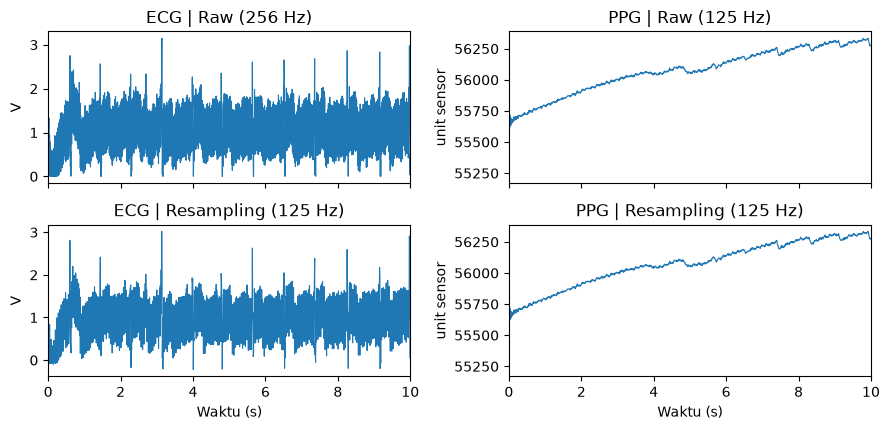

In [4]:
from math import gcd
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.signal import butter, resample_poly, sosfiltfilt

folder = Path.home() / "Documents" / "Farid ITS" / "Tugas Akhir" / "scratch" / "gemastik" / "Bp revisi" / "Data"
file_ecg = {p.stem.removesuffix("_ecg"): p for p in (folder / "ECG").glob("*_ecg.csv")}
file_ppg = {p.stem.removesuffix("_ppg"): p for p in (folder / "PPG").glob("*_ppg.csv")}
pasangan = sorted(file_ecg.keys() & file_ppg.keys())
if not pasangan:
    raise FileNotFoundError(f"Tidak ada pasangan ECG dan PPG di {folder}")

contoh = pasangan[0]
data_ecg = pd.read_csv(file_ecg[contoh])
data_ppg = pd.read_csv(file_ppg[contoh])
raw = [
    (data_ecg["Time (s)"].to_numpy(), data_ecg["ECG_Raw (V)"].to_numpy()),
    (data_ppg["Time (s)"].to_numpy(), data_ppg["PPG_IR"].to_numpy()),
]
fs_target = 125

def resampling_anti_alias(sinyal, fs_asal, fs_tujuan):
    pembagi = gcd(fs_asal, fs_tujuan)
    return resample_poly(sinyal, fs_tujuan // pembagi, fs_asal // pembagi)

laju_asal, hasil_resampling = [], []
for waktu, sinyal in raw:
    if len(waktu) < 2 or not np.isfinite(waktu).all() or not np.isfinite(sinyal).all():
        raise ValueError("Rekaman contoh mengandung nilai kosong atau tidak valid.")
    interval = np.diff(waktu)
    median_interval = np.median(interval)
    if median_interval <= 0 or not np.allclose(interval, median_interval, rtol=0.01, atol=0):
        raise ValueError("Timestamp contoh harus berurutan dan hampir seragam.")
    fs_asal = round(1 / median_interval)
    laju_asal.append(fs_asal)
    if fs_asal != fs_target:
        sinyal = resampling_anti_alias(sinyal, fs_asal, fs_target)
        waktu = waktu[0] + np.arange(len(sinyal)) / fs_target
    hasil_resampling.append((waktu, sinyal))

awal = max(waktu[0] for waktu, _ in hasil_resampling)
akhir = min(min(waktu[-1] for waktu, _ in hasil_resampling), *(waktu[-1] for waktu, _ in raw))
waktu_sync = awal + np.arange(int(np.floor((akhir - awal) * fs_target + 1e-9)) + 1) / fs_target
if len(waktu_sync) < 10 * fs_target:
    raise ValueError("Durasi kedua kanal yang bertumpang tindih kurang dari 10 detik.")
ecg_sync, ppg_sync = [np.interp(waktu_sync, waktu, sinyal) for waktu, sinyal in hasil_resampling]
resampled = [(waktu_sync, ecg_sync), (waktu_sync, ppg_sync)]

def plot_tahapan(tahapan):
    fig, axes = plt.subplots(len(tahapan), 2, figsize=(9, 2.2 * len(tahapan)), sharex=True)
    for baris, (tahap, kanal, laju) in enumerate(tahapan):
        for kolom, (nama, satuan) in enumerate((("ECG", "V"), ("PPG", "unit sensor"))):
            waktu, sinyal = kanal[kolom]
            detik = waktu - awal
            tampil = (detik >= 0) & (detik < 10)
            ax = axes[baris, kolom]
            ax.plot(detik[tampil], sinyal[tampil], linewidth=0.8)
            ax.set(title=f"{nama} | {tahap} ({laju[kolom]} Hz)", ylabel=satuan, xlim=(0, 10))
    for ax in axes[-1]:
        ax.set_xlabel("Waktu (s)")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

tahapan = [("Raw", raw, laju_asal), ("Resampling", resampled, [fs_target] * 2)]
plot_tahapan(tahapan)

## Filtering

Ikuti filter fisiologis dari `Bp revisi/stage1.py:27,50–77`. Balik polaritas PPG IR sesuai skrip acuan, lalu gunakan Butterworth orde 4 dengan penyaringan dua arah. ECG memakai **0,5–40 Hz**, sedangkan PPG memakai **0,5–10 Hz**. Batas bawah membantu meredam baseline yang berubah lambat. Filter ini diterapkan setelah resampling dan memiliki fungsi berbeda dari filter anti-alias.

Grafik menampilkan raw, hasil resampling, dan hasil filtering dari atas ke bawah. Semua panel memakai 10 detik pertama pada interval yang sama.

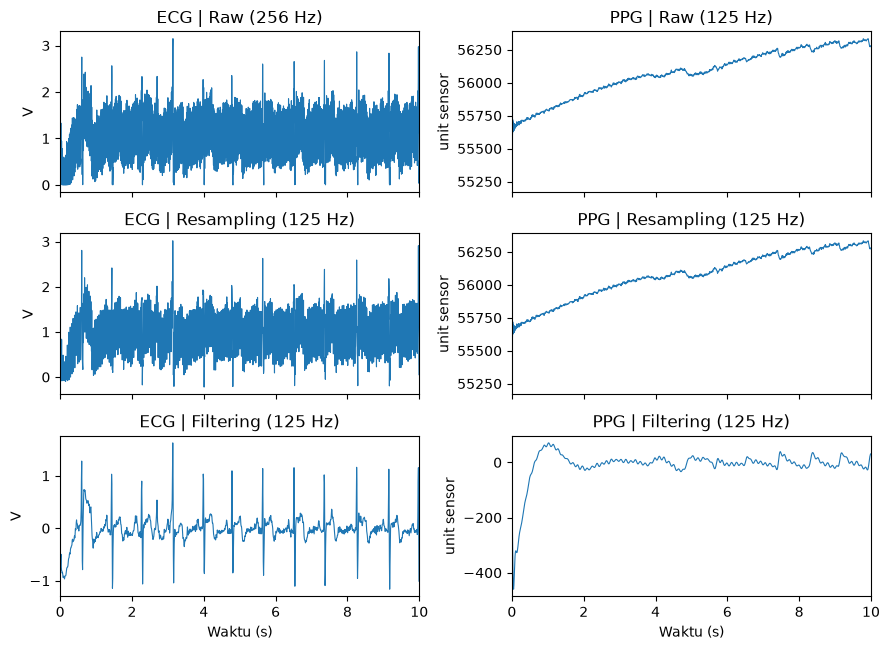

In [5]:
def filter_bandpass(sinyal, batas_bawah, batas_atas):
    sos = butter(4, [batas_bawah, batas_atas], btype="bandpass", fs=fs_target, output="sos")
    return sosfiltfilt(sos, sinyal)

ecg_filter = filter_bandpass(ecg_sync, 0.5, 40.0)
ppg_filter = filter_bandpass(-ppg_sync, 0.5, 10.0)
filtered = [(waktu_sync, ecg_filter), (waktu_sync, ppg_filter)]
assert len(ecg_filter) == len(ppg_filter) == len(waktu_sync)
assert np.isfinite(ecg_filter).all() and np.isfinite(ppg_filter).all()
plot_tahapan([*tahapan, ("Filtering", filtered, [fs_target] * 2)])

## Cek anti-aliasing

Uji terkontrol memakai komponen 10 Hz dan 90 Hz pada laju ECG contoh. Pada 125 Hz, komponen 90 Hz dapat muncul sebagai alias 35 Hz. Tabel membandingkan resampling polifase dengan interpolasi tanpa filter anti-alias. Uji ini mengukur penekanan alias pada sinyal uji. Grafik di atas tetap memakai rekaman asli.

In [6]:
def amplitudo(sinyal, waktu, hz):
    return 2 * abs(np.mean(sinyal * np.exp(-2j * np.pi * hz * waktu)))

fs_uji = laju_asal[0]
waktu_uji = np.arange(8 * fs_uji) / fs_uji
uji = np.sin(2 * np.pi * 10 * waktu_uji) + np.sin(2 * np.pi * 90 * waktu_uji)
hasil = resampling_anti_alias(uji, fs_uji, fs_target)
waktu_hasil = np.arange(len(hasil)) / fs_target
kontrol = np.interp(waktu_hasil, waktu_uji, uji)
tengah = (waktu_hasil >= 2) & (waktu_hasil < 6)
waktu_tengah = waktu_hasil[tengah]
galat = abs(amplitudo(hasil[tengah], waktu_tengah, 10) - 1)
alias_kontrol = amplitudo(kontrol[tengah], waktu_tengah, 35)
alias_hasil = amplitudo(hasil[tengah], waktu_tengah, 35)
penekanan_db = 20 * np.log10(alias_kontrol / max(alias_hasil, np.finfo(float).eps))
display(pd.DataFrame({"Galat amplitudo 10 Hz (%)": [100 * galat], "Penekanan alias 35 Hz (dB)": [penekanan_db]}).round(3))
assert galat <= 0.05 and penekanan_db >= 20, "Uji anti-alias belum memenuhi kriteria."

,Galat amplitudo 10 Hz (%),Penekanan alias 35 Hz (dB)
0,0.037,58.903


# Stage 3 — Segmentasi, SQI, dan tujuh kanal

Gunakan segmen PulseDB dari Stage 1. Setiap segmen sudah berdurasi 10 detik dengan 1.250 sampel pada 125 Hz. ECG, PPG, SBP, DBP, dan grup tetap berpasangan. Rekaman primer pada Stage 2 hanya digunakan untuk demonstrasi.

## Signal Quality Index (SQI)

Terapkan aturan `remote_jobs/pulsedb_calbased/train_calbased.py:36` pada ECG dan PPG yang dinormalisasi. Periksa jumlah puncak, kesesuaian jumlah puncak antarkanal, keteraturan interval PPG, serta rasio daya spektral pada pita jantung. SQI tambahan ini memakai ECG dan PPG. Seleksi awal PulseDB dan audit label di Stage 1 adalah tahap terpisah. Tabel menghitung alasan pertama yang gagal.

,Segmen,Subjek
Sebelum SQI,4721,40
Sesudah SQI,3865,39


,Jumlah segmen
Lolos,3865
"Interval puncak PPG tidak teratur (CV > 0,15)",392
Selisih jumlah puncak ECG-PPG lebih dari 1,368
Jumlah puncak di luar 7-22,95
"Rasio daya pita jantung di bawah 0,65",1


Contoh ditolak: Selisih jumlah puncak ECG-PPG lebih dari 1


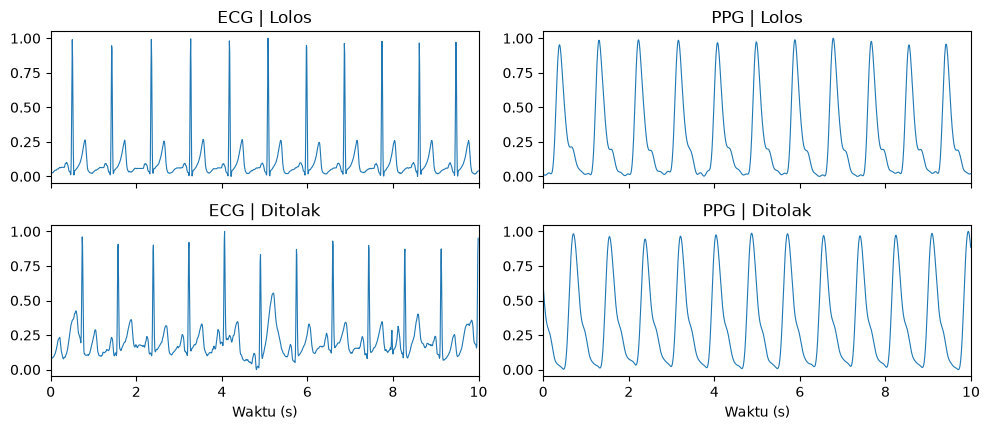

In [7]:
from scipy.signal import find_peaks, hilbert, welch

def zscore(sinyal):
    return (sinyal - np.mean(sinyal)) / (np.std(sinyal) + 1e-6)

def alasan_sqi(ecg, ppg, fs=FS_PULSEDB):
    r, _ = find_peaks(ecg, distance=int(fs * 0.4), prominence=0.8)
    p, _ = find_peaks(ppg, distance=int(fs * 0.4), prominence=0.5)
    if not (7 <= len(r) <= 22 and 7 <= len(p) <= 22):
        return "Jumlah puncak di luar 7-22"
    if abs(len(r) - len(p)) > 1:
        return "Selisih jumlah puncak ECG-PPG lebih dari 1"
    interval = np.diff(p)
    if np.std(interval) / (np.mean(interval) + 1e-6) > 0.15:
        return "Interval puncak PPG tidak teratur (CV > 0,15)"
    f, psd = welch(ppg, fs=fs, nperseg=256)
    daya_jantung = psd[(f >= 0.8) & (f <= 3.5)].sum()
    daya_total = psd[(f >= 0.5) & (f <= 15)].sum() + 1e-8
    if daya_jantung / daya_total < 0.65:
        return "Rasio daya pita jantung di bawah 0,65"
    return "Lolos"

assert all(s["ecg"].shape == s["ppg"].shape == (SAMPEL_PER_SEGMEN,) and s["fs_hz"] == FS_PULSEDB
           for s in segmen_pulsedb)
status_sqi = [alasan_sqi(zscore(s["ecg"]), zscore(s["ppg"])) for s in segmen_pulsedb]
segmen_lolos = [s for s, status in zip(segmen_pulsedb, status_sqi) if status == "Lolos"]
if not segmen_lolos:
    raise ValueError("Tidak ada segmen yang lolos SQI.")
display(pd.DataFrame({
    "Segmen": [len(segmen_pulsedb), len(segmen_lolos)],
    "Subjek": [len({s["grup"] for s in data}) for data in (segmen_pulsedb, segmen_lolos)],
}, index=["Sebelum SQI", "Sesudah SQI"]))
display(pd.Series(status_sqi).value_counts().rename("Jumlah segmen").to_frame())

contoh_sqi = [(segmen_lolos[0], "Lolos")]
ditolak = next(((s, status) for s, status in zip(segmen_pulsedb, status_sqi) if status != "Lolos"), None)
if ditolak is not None:
    contoh_sqi.append(ditolak)
    print("Contoh ditolak:", ditolak[1])
waktu_sqi = np.arange(SAMPEL_PER_SEGMEN) / FS_PULSEDB
fig, axes = plt.subplots(len(contoh_sqi), 2, squeeze=False, figsize=(10, 2.2 * len(contoh_sqi)), sharex=True)
for baris, (segmen, status) in enumerate(contoh_sqi):
    for kolom, kanal in enumerate(("ecg", "ppg")):
        ax = axes[baris, kolom]
        ax.plot(waktu_sqi, segmen[kanal], linewidth=0.8)
        ax.set(title=f"{kanal.upper()} | {'Lolos' if status == 'Lolos' else 'Ditolak'}", xlim=(0, 10))
for ax in axes[-1]:
    ax.set_xlabel("Waktu (s)")
fig.tight_layout()
plt.show()
plt.close(fig)

## Bentuk input CNN–BiGRU

Ikuti `extract_pulsedb.py:13–28`. VPG adalah turunan diskret PPG dan APG adalah turunan diskret VPG. Perkalian ECG–PPG dilakukan per sampel. Amplop ECG dan PPG dihitung dari magnitudo transformasi Hilbert. Tiap kanal dinormalisasi dalam segmennya. Grafik menunjukkan tujuh kanal dari satu segmen lolos selama 10 detik.

Bentuk tensor (segmen, sampel, kanal): (3865, 1250, 7)


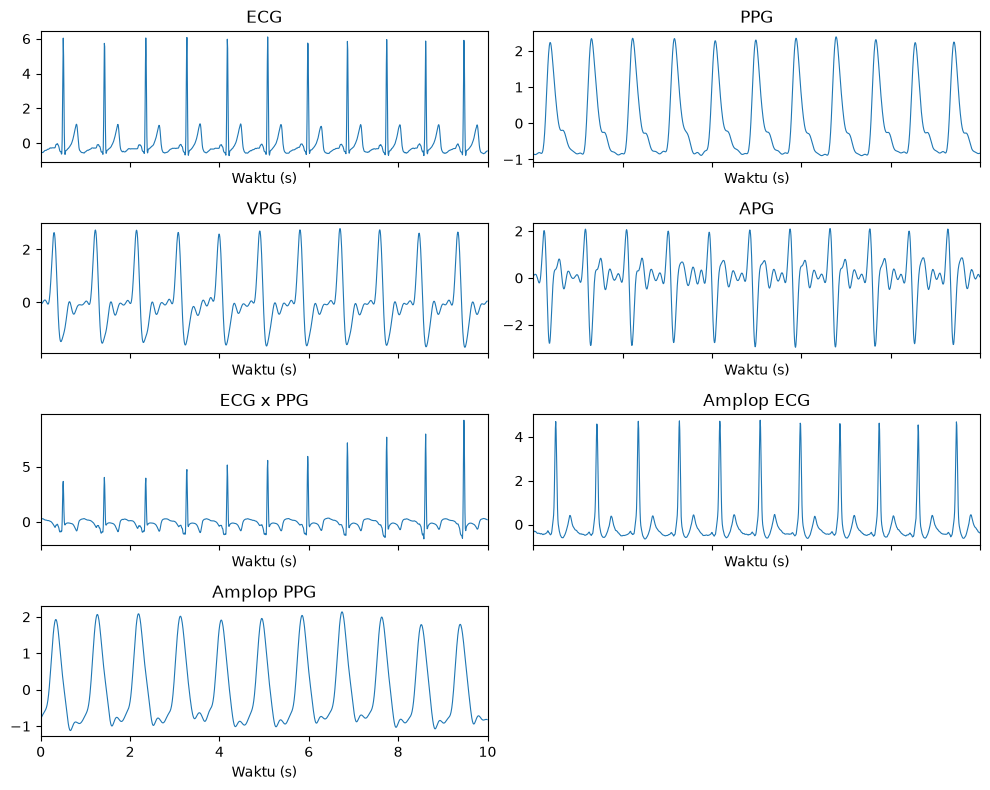

In [8]:
nama_kanal = ["ECG", "PPG", "VPG", "APG", "ECG x PPG", "Amplop ECG", "Amplop PPG"]

def bentuk_7_kanal(segmen):
    ecg, ppg = zscore(segmen["ecg"]), zscore(segmen["ppg"])
    vpg = zscore(np.gradient(ppg))
    apg = zscore(np.gradient(vpg))
    return np.column_stack([
        ecg, ppg, vpg, apg, zscore(ecg * ppg),
        zscore(np.abs(hilbert(ecg))), zscore(np.abs(hilbert(ppg))),
    ]).astype(np.float32)

X_pulsedb = np.stack([bentuk_7_kanal(s) for s in segmen_lolos])
sbp_pulsedb = np.array([s["sbp_mmhg"] for s in segmen_lolos], dtype=np.float32)
dbp_pulsedb = np.array([s["dbp_mmhg"] for s in segmen_lolos], dtype=np.float32)
grup_pulsedb = [s["grup"] for s in segmen_lolos]

assert X_pulsedb.shape == (len(segmen_lolos), 1250, 7)
assert len(X_pulsedb) == len(sbp_pulsedb) == len(dbp_pulsedb) == len(grup_pulsedb)
assert all(np.isfinite(data).all() for data in (X_pulsedb, sbp_pulsedb, dbp_pulsedb))
print("Bentuk tensor (segmen, sampel, kanal):", X_pulsedb.shape)

fig, axes = plt.subplots(4, 2, figsize=(10, 8), sharex=True)
for indeks, (ax, nama) in enumerate(zip(axes.flat, nama_kanal)):
    ax.plot(waktu_sqi, X_pulsedb[0, :, indeks], linewidth=0.8)
    ax.set(title=nama, xlabel="Waktu (s)", xlim=(0, 10))
axes[-1, -1].set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)

# Stage 4 — BPNet

Stage ini membangun arsitektur BPNet dan menampilkan riwayat pelatihan PulseDB yang sudah tersimpan. Kurva historis dan pembagian data dari Stage 3 ditampilkan terpisah agar asal hasilnya jelas.

## Pembagian dan normalisasi target

Ikuti skema acuan: acak segmen di dalam setiap subjek dengan seed 42 dan sisihkan sekitar 10% untuk validasi. Subjek dengan kurang dari lima segmen tidak masuk pembagian ini. Satu segmen latih per subjek dicatat sebagai acuan untuk kalibrasi nanti. Subjek yang sama bisa muncul di latih dan validasi, tetapi indeks segmennya terpisah. Rerata dan simpangan baku SBP/DBP dihitung hanya dari data latih.

Acuan pembagian: `remote_jobs/pulsedb_calbased/train_calbased.py:305–335`.

In [9]:
from collections import defaultdict

def bagi_pulsedb(grup):
    per_subjek = defaultdict(list)
    for indeks, subjek in enumerate(grup):
        per_subjek[subjek].append(indeks)

    rng = np.random.RandomState(42)
    latih, validasi, acuan = [], [], {}
    for subjek in sorted(per_subjek):
        indeks = per_subjek[subjek]
        if len(indeks) < 5:
            continue
        acak = rng.permutation(indeks)
        jumlah_validasi = max(1, len(indeks) // 10)
        latih.extend(acak[jumlah_validasi:])
        validasi.extend(acak[:jumlah_validasi])
        acuan[subjek] = acak[jumlah_validasi]
    return np.asarray(latih, dtype=int), np.asarray(validasi, dtype=int), acuan

indeks_latih, indeks_validasi, acuan_pulsedb = bagi_pulsedb(grup_pulsedb)
if not indeks_latih.size or not indeks_validasi.size:
    raise ValueError("Segmen tidak cukup untuk pembagian latih dan validasi.")
assert not set(indeks_latih).intersection(indeks_validasi)
assert set(acuan_pulsedb.values()).issubset(indeks_latih)
target_pulsedb = np.column_stack([sbp_pulsedb, dbp_pulsedb])
rerata_target = target_pulsedb[indeks_latih].mean(axis=0)
simpangan_target = target_pulsedb[indeks_latih].std(axis=0)
if (simpangan_target <= 0).any():
    raise ValueError("Simpangan baku target latih harus positif.")
target_normal = (target_pulsedb - rerata_target) / simpangan_target
display(pd.DataFrame({
    "Segmen": [len(indeks_latih), len(indeks_validasi)],
    "Subjek": [len({grup_pulsedb[i] for i in indeks}) for indeks in (indeks_latih, indeks_validasi)],
}, index=["Latih", "Validasi"]))

,Segmen,Subjek
Latih,3491,36
Validasi,369,36


## Arsitektur BPNet

CNN mengekstrak fitur lokal dengan beberapa ukuran kernel. BiGRU membaca urutan fitur dari dua arah. Attention dan pooling merangkum informasi satu segmen, lalu dua bagian keluaran memprediksi SBP dan DBP yang masih ternormalisasi.

Fungsi pembangun memakai arsitektur yang sama dengan eksperimen PulseDB. Uji opsional membuat bobot baru dan memeriksa satu langkah optimizer. Setel `UJI_BATCH = True` setelah PyTorch tersedia untuk menjalankannya. Uji ini terpisah dari riwayat pelatihan dan tidak menghasilkan bobot untuk transfer learning.

Acuan arsitektur dan loss: `remote_jobs/pulsedb_calbased/train_calbased.py:76–223`.

In [10]:
def buat_bpnet():
    from typing import Tuple
    import torch
    from torch import nn

    class InceptionBlock1D(nn.Module):
        """Multi-scale 1D Inception module with parallel temporal kernels (1, 3, 7, 15)."""
        def __init__(self, in_channels: int, filters: int = 64):
            super().__init__()
            b = filters // 4
            self.b1 = nn.Conv1d(in_channels, b, kernel_size=1, padding=0)
            self.b2 = nn.Conv1d(in_channels, b, kernel_size=3, padding=1)
            self.b3 = nn.Conv1d(in_channels, b, kernel_size=7, padding=3)
            self.b4 = nn.Conv1d(in_channels, b, kernel_size=15, padding=7)
            self.act = nn.SiLU()
            self.bn = nn.BatchNorm1d(filters)

        def forward(self, x: torch.Tensor) -> torch.Tensor:
            out = torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)
            return self.bn(self.act(out))


    class BPNet(nn.Module):
        """CNN-BiGRU untuk estimasi SBP dan DBP dari tujuh kanal."""
        def __init__(
            self,
            in_channels: int = 7,
            stem_ch: int = 48,
            inc1_ch: int = 64,
            inc2_ch: int = 96,
            inc3_ch: int = 128,
            gru_hid: int = 64,
            num_heads: int = 4,
        ):
            super().__init__()
            self.stem = nn.Sequential(
                nn.Conv1d(in_channels, stem_ch, kernel_size=7, stride=2, padding=3),
                nn.BatchNorm1d(stem_ch),
                nn.SiLU(),
            )
            self.inc1 = InceptionBlock1D(stem_ch, inc1_ch)
            self.pool1 = nn.MaxPool1d(2)
            self.drop1 = nn.Dropout(0.15)

            self.inc2 = InceptionBlock1D(inc1_ch, inc2_ch)
            self.pool2 = nn.MaxPool1d(2)
            self.drop2 = nn.Dropout(0.15)

            self.inc3 = InceptionBlock1D(inc2_ch, inc3_ch)
            self.pool3 = nn.MaxPool1d(2)
            self.drop3 = nn.Dropout(0.20)

            self.bigru = nn.GRU(
                input_size=inc3_ch,
                hidden_size=gru_hid,
                num_layers=2,
                batch_first=True,
                bidirectional=True,
                dropout=0.15,
            )
            self.mhsa = nn.MultiheadAttention(
                embed_dim=gru_hid * 2,
                num_heads=num_heads,
                dropout=0.10,
                batch_first=True,
            )
            self.ln = nn.LayerNorm(gru_hid * 2)

            # Dual Global Context Pooling (Avg + Max = 256)
            context_dim = gru_hid * 4
            self.context_drop = nn.Dropout(0.20)

            self.sbp_head = nn.Sequential(
                nn.Linear(context_dim, 96),
                nn.BatchNorm1d(96),
                nn.SiLU(),
                nn.Dropout(0.15),
                nn.Linear(96, 1),
            )
            self.dbp_head = nn.Sequential(
                nn.Linear(context_dim, 96),
                nn.BatchNorm1d(96),
                nn.SiLU(),
                nn.Dropout(0.15),
                nn.Linear(96, 1),
            )

        def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
            if x.shape[1] == 1250:
                x = x.transpose(1, 2)
            x = self.stem(x)
            x = self.drop1(self.pool1(self.inc1(x)))
            x = self.drop2(self.pool2(self.inc2(x)))
            x = self.drop3(self.pool3(self.inc3(x)))

            x = x.transpose(1, 2)
            gru_out, _ = self.bigru(x)
            attn_out, _ = self.mhsa(gru_out, gru_out, gru_out)
            x = self.ln(gru_out + attn_out)

            avg_p = x.mean(dim=1)
            max_p = x.max(dim=1).values
            context = self.context_drop(torch.cat([avg_p, max_p], dim=1))

            sbp_z = self.sbp_head(context).squeeze(-1)
            dbp_z = self.dbp_head(context).squeeze(-1)
            return sbp_z, dbp_z


    # ==============================================================================
    # Step 3: Physics-Informed BHS Loss
    # ==============================================================================

    class PhysicsBHSLoss(nn.Module):
        def __init__(self, s_mean: float, s_std: float, d_mean: float, d_std: float):
            super().__init__()
            self.s_mean = s_mean
            self.s_std = s_std
            self.d_mean = d_mean
            self.d_std = d_std
            self.huber = nn.SmoothL1Loss(beta=0.20)

        def forward(
            self,
            s_pred_z: torch.Tensor,
            d_pred_z: torch.Tensor,
            s_true_z: torch.Tensor,
            d_true_z: torch.Tensor,
        ) -> torch.Tensor:
            loss_huber = self.huber(s_pred_z, s_true_z) + self.huber(d_pred_z, d_true_z)

            s_pred = s_pred_z * self.s_std + self.s_mean
            d_pred = d_pred_z * self.d_std + self.d_mean
            s_true = s_true_z * self.s_std + self.s_mean
            d_true = d_true_z * self.d_std + self.d_mean

            map_err = torch.mean(torch.abs((s_pred + 2.0 * d_pred) / 3.0 - (s_true + 2.0 * d_true) / 3.0)) / 15.0
            pp_err = torch.mean(torch.abs((s_pred - d_pred) - (s_true - d_true))) / 15.0

            s_abs = torch.abs(s_pred - s_true)
            d_abs = torch.abs(d_pred - d_true)
            bhs_pen = (
                torch.mean(torch.relu(s_abs - 4.0))
                + torch.mean(torch.relu(d_abs - 3.5)) * 1.2
            ) / 10.0

            return loss_huber + 0.15 * map_err + 0.15 * pp_err + 0.25 * bhs_pen


    # ==============================================================================

    return BPNet(), PhysicsBHSLoss

UJI_BATCH = False
if UJI_BATCH:
    import torch

    torch.manual_seed(42)
    model_uji, kelas_loss = buat_bpnet()
    loss_bpnet = kelas_loss(rerata_target[0], simpangan_target[0], rerata_target[1], simpangan_target[1])
    batch = indeks_latih[:4]
    if len(batch) < 2:
        raise ValueError("Uji batch membutuhkan minimal dua segmen.")
    input_uji = torch.as_tensor(X_pulsedb[batch], dtype=torch.float32)
    target_uji = torch.as_tensor(target_normal[batch], dtype=torch.float32)
    optimizer = torch.optim.AdamW(model_uji.parameters(), lr=1e-3, weight_decay=5e-3)
    bobot_awal = model_uji.sbp_head[-1].weight.detach().clone()
    optimizer.zero_grad()
    prediksi_sbp, prediksi_dbp = model_uji(input_uji)
    assert prediksi_sbp.shape == prediksi_dbp.shape == (len(batch),)
    loss = loss_bpnet(prediksi_sbp, prediksi_dbp, target_uji[:, 0], target_uji[:, 1])
    assert torch.isfinite(loss)
    loss.backward()
    optimizer.step()
    assert not torch.equal(bobot_awal, model_uji.sbp_head[-1].weight.detach())
    print(f"Uji satu batch lulus. Loss: {loss.item():.4f}")
else:
    print("Uji satu batch belum dijalankan. Kurva berikut memakai riwayat pelatihan.")


Uji satu batch belum dijalankan. Kurva berikut memakai riwayat pelatihan.


## Kurva loss dari pelatihan sebelumnya

Baca `training_history.csv` dan ringkasan dari direktori run PulseDB yang sama. Garis putus-putus menandai epoch yang dipilih menurut kriteria eksperimen sumber. Nilainya tidak harus berada pada titik validation loss terendah.

Riwayat ini berasal dari run sebelumnya. Jumlah segmen yang lolos SQI pada run tersebut berbeda dari hasil Stage 3 saat ini. Checkpoint dari run yang sama tersedia sebagai sumber bobot historis untuk tahap transfer learning setelah diperiksa. Sel ini hanya membaca riwayat dan belum memuat checkpoint.

Run historis: 80 epoch, 3,869 segmen lolos SQI.
Epoch checkpoint: 75 | Checkpoint tersedia: ya


,epoch,train_loss,val_loss
74,75,0.2459,0.4043


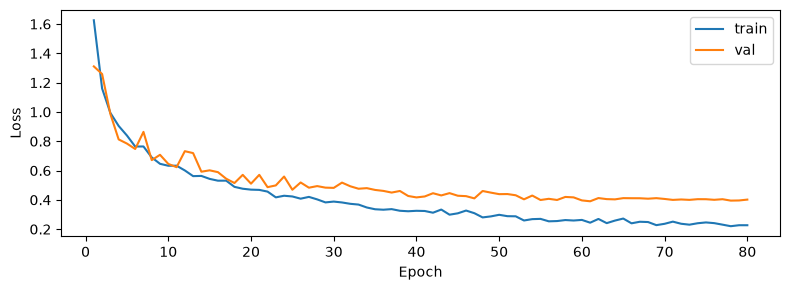

In [11]:
import json
from pathlib import Path

folder_run = (Path.home() / "Documents" / "Farid ITS" / "Tugas Akhir" / "scratch" / "gemastik"
              / "remote_jobs" / "pulsedb_calbased" / "output_v3" / "output")
riwayat_bpnet = pd.read_csv(folder_run / "training_history.csv")
ringkasan_run = json.loads((folder_run / "stage3_calbased_summary.json").read_text(encoding="utf-8"))
CHECKPOINT_BPNET = folder_run / "model_best.pt"

kolom_loss = ["epoch", "train_loss", "val_loss"]
if riwayat_bpnet.empty or not set(kolom_loss).issubset(riwayat_bpnet):
    raise ValueError("Riwayat harus memiliki epoch, train_loss, dan val_loss.")
if not np.isfinite(riwayat_bpnet[kolom_loss]).all().all() or not riwayat_bpnet["epoch"].is_unique:
    raise ValueError("Riwayat berisi nilai tidak valid atau epoch ganda.")
riwayat_bpnet = riwayat_bpnet.sort_values("epoch")
epoch_terpilih = ringkasan_run["epoch"]
assert epoch_terpilih in set(riwayat_bpnet["epoch"])
print(f"Run historis: {len(riwayat_bpnet)} epoch, {ringkasan_run['sqi_kept_segments']:,} segmen lolos SQI.")
print(f"Epoch checkpoint: {epoch_terpilih} | Checkpoint tersedia: {'ya' if CHECKPOINT_BPNET.is_file() else 'tidak'}")
display(riwayat_bpnet.loc[riwayat_bpnet["epoch"].eq(epoch_terpilih), kolom_loss])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(riwayat_bpnet["epoch"], riwayat_bpnet["train_loss"], label="train")
ax.plot(riwayat_bpnet["epoch"], riwayat_bpnet["val_loss"], label="val")
ax.set(xlabel="Epoch", ylabel="Loss")
fig.tight_layout()
plt.legend(loc='upper right')
plt.show()
plt.close(fig)

# Stage 5 — Validasi BPNet pada PulseDB

Tabel memakai checkpoint **epoch terpilih** dari run historis Stage 4. MAE adalah rata-rata besar selisih terhadap nilai rujukan, dalam mmHg. Baris persentase menunjukkan proporsi prediksi dalam toleransi galat.

### Kalibrasi satu titik

Untuk setiap subjek, ambil nilai rujukan dan prediksi BPNet pada satu segmen acuan dari data latih. Terapkan koreksi terpisah untuk SBP dan DBP:

$$
\text{offset}=y_{\mathrm{acuan}}-\widehat y_{\mathrm{acuan}},
\qquad
\widehat y_{\mathrm{koreksi}}=\widehat y+0.35\times\text{offset}.
$$

MAE latih berasal dari riwayat sebelum koreksi tersebut. MAE dan persentase toleransi validasi memakai prediksi yang sudah dikoreksi. Segmen acuan tidak ikut dihitung dalam metrik validasi. Segmen validasi ikut menentukan checkpoint terpilih.

**Sumber:** `training_history.csv` dan `stage3_calbased_summary.json` dari run PulseDB `output_v3`. Prosedur kalibrasi ada di `train_calbased.py:417–449`. Ringkasan yang tersedia tidak memuat prediksi per segmen atau metrik validasi tanpa kalibrasi.

In [12]:
baris_epoch = riwayat_bpnet.loc[riwayat_bpnet["epoch"].eq(epoch_terpilih)].iloc[0]
tabel_validasi_bpnet = pd.DataFrame({
    tekanan.upper(): [
        baris_epoch[f"train_{tekanan}_mae"],
        ringkasan_run[tekanan]["mae"],
        ringkasan_run[tekanan]["pct_le_5"],
        ringkasan_run[tekanan]["pct_le_10"],
        ringkasan_run[tekanan]["pct_le_15"],
    ]
    for tekanan in ("sbp", "dbp")
}, index=[
    "MAE latih (mmHg)",
    "MAE validasi dengan kalibrasi (mmHg)",
    "Galat absolut validasi ≤ 5 mmHg (%)",
    "Galat absolut validasi ≤ 10 mmHg (%)",
    "Galat absolut validasi ≤ 15 mmHg (%)",
])
tabel_validasi_bpnet.index.name = "Metrik"
for tekanan in ("sbp", "dbp"):
    assert np.isclose(baris_epoch[f"val_{tekanan}_mae"], ringkasan_run[tekanan]["mae"])
    assert np.isclose(baris_epoch[f"train_{tekanan}_mae"], ringkasan_run[f"train_{tekanan}_mae"])

print(f"Validasi PulseDB historis: epoch {epoch_terpilih}, {ringkasan_run['test_segments']} segmen.")
display(tabel_validasi_bpnet.round(2))

Validasi PulseDB historis: epoch 75, 369 segmen.


,SBP,DBP
Metrik,,
MAE latih (mmHg),3.00,1.93
MAE validasi dengan kalibrasi (mmHg),4.04,2.50
Galat absolut validasi ≤ 5 mmHg (%),75.61,86.72
Galat absolut validasi ≤ 10 mmHg (%),92.41,97.02
Galat absolut validasi ≤ 15 mmHg (%),95.66,98.64


# Stage 6 — Persiapan data primer TriaGo

## Muat data dan EDA

Cocokkan rekaman ECG dan PPG melalui `subject_id`, lalu ambil SBP dan DBP dari `metadata/target.csv`. Gunakan `patient_id` sebagai grup untuk split per peserta di Stage 7. Satu peserta dapat memiliki beberapa rekaman. Tabel hanya menampilkan agregat.

Pemeriksaan label mengikuti `Bp revisi/stage2.py:33`. Label SBP dan DBP melekat pada rekaman. Setiap segmen dari rekaman yang sama menerima pasangan label tersebut.

In [13]:
from collections import Counter

metadata_primer = pd.read_csv(
    folder / "metadata" / "target.csv",
    usecols=["subject_id", "patient_id", "SBP", "DBP"],
    dtype={"subject_id": "string", "patient_id": "string"},
)
metadata_primer[["subject_id", "patient_id"]] = metadata_primer[["subject_id", "patient_id"]].apply(lambda id_: id_.str.strip())
id_kosong = metadata_primer[["subject_id", "patient_id"]].fillna("").eq("").any(axis=1)
if id_kosong.any() or metadata_primer["subject_id"].duplicated().any():
    raise ValueError("Metadata primer mengandung ID kosong atau ID rekaman ganda.")

tekanan = metadata_primer[["SBP", "DBP"]].apply(pd.to_numeric, errors="coerce")
label_valid = tekanan["SBP"].between(70, 200) & tekanan["DBP"].between(40, 120) & tekanan["SBP"].gt(tekanan["DBP"])
punya_pasangan = metadata_primer["subject_id"].isin(pasangan)
metadata_valid = metadata_primer.assign(SBP=tekanan["SBP"], DBP=tekanan["DBP"]).loc[label_valid & punya_pasangan]
print(f"Rekaman di metadata: {len(metadata_primer)} | Tanpa pasangan: {(~punya_pasangan).sum()}")
print(f"Label kosong/tidak valid: {(~label_valid).sum()} | Masuk persiapan: {len(metadata_valid)}")
display(metadata_valid[["SBP", "DBP"]].describe().round(2))

Rekaman di metadata: 94 | Tanpa pasangan: 0
Label kosong/tidak valid: 2 | Masuk persiapan: 92


,SBP,DBP
count,92.00,92.00
mean,114.93,75.40
std,15.23,8.49
min,91.00,60.00
25%,105.00,68.75
50%,112.00,75.00
75%,121.25,80.25
max,161.00,98.00


## Resampling, filtering, dan segmentasi 10 detik

Gunakan kembali resampling polifase dan filter dari Stage 2. Proses tiap kanal pada laju yang ditunjukkan timestamp, lalu sejajarkan pada grid 125 Hz. Perbedaan terhadap skrip awal TriaGo adalah filter anti-alias diterapkan sebelum penurunan laju, kemudian grid bersama dibentuk. Filter fisiologis dan pembalikan polaritas PPG mengikuti sumber.

Ambil jendela **10 detik** setiap **2 detik**. SQI primer mengecek sinyal datar, kesesuaian denyut ECG dan PPG, bentuk gelombang PPG, serta daya spektral. Aturannya berasal dari `Bp revisi/stage1.py:88–184`. Perbandingan raw, resampling, dan filtering serta uji anti-alias tersedia di Stage 2.

In [14]:
from typing import Dict, Tuple

from scipy.signal import find_peaks, welch
from scipy.stats import kurtosis, skew

def evaluate_segment_sqi(ecg_seg: np.ndarray, ppg_seg: np.ndarray, fs: float = 125.0) -> Tuple[bool, str, Dict[str, float]]:
    """Multimodal Signal Quality Index (SQI) assessment for 10-second segments:
    
    1. Checks for NaNs, Infs, and sensor flatline.
    2. Pan-Tompkins QRS energy operator for robust ECG R-peak detection.
    3. Prominence peak detection for PPG pulsatile waves.
    4. Physiological Heart Rate bounds: [40, 180] BPM.
    5. Dual-channel HR concordance: |HR_ecg - HR_ppg| <= 6.0 BPM.
    6. Morphological criteria: PPG Skewness > -0.15, Kurtosis >= 1.8.
    7. Spectral SNR: >= 50% relative power in cardiac band (0.5 - 8.0 Hz).
    """
    if not np.isfinite(ecg_seg).all() or not np.isfinite(ppg_seg).all():
        return False, "NaN/Inf Present", {}
    if np.std(ecg_seg) < 1e-4 or np.std(ppg_seg) < 1e-4:
        return False, "Flatline Signal", {}

    # 1. ECG QRS Detection via Energy Operator (derivative^2 + MWI)
    d_ecg = np.diff(ecg_seg, prepend=ecg_seg[0])
    mwi_ecg = np.convolve(d_ecg**2, np.ones(18) / 18, mode="same")
    ecg_peaks, _ = find_peaks(mwi_ecg, distance=int(0.4 * fs), prominence=0.3 * np.std(mwi_ecg))

    # 2. PPG Systolic Peak Detection
    ppg_peaks, _ = find_peaks(ppg_seg, distance=int(0.4 * fs), prominence=0.25 * np.std(ppg_seg))

    if len(ecg_peaks) < 4:
        return False, f"ECG Peaks Insufficient ({len(ecg_peaks)})", {}
    if len(ppg_peaks) < 4:
        return False, f"PPG Peaks Insufficient ({len(ppg_peaks)})", {}

    # 3. Heart Rate Calculation & Concordance
    hr_ecg = 60.0 / np.mean(np.diff(ecg_peaks) / fs)
    hr_ppg = 60.0 / np.mean(np.diff(ppg_peaks) / fs)

    if not (40.0 <= hr_ecg <= 180.0) or not (40.0 <= hr_ppg <= 180.0):
        return False, f"HR Out of Bounds (ECG:{hr_ecg:.0f}, PPG:{hr_ppg:.0f})", {}

    hr_diff = abs(hr_ecg - hr_ppg)
    if hr_diff > 6.0:
        return False, f"HR Discordance (Diff:{hr_diff:.1f} bpm)", {}

    # 4. Statistical Morphological Metrics
    s_val = float(skew(ppg_seg))
    k_val = float(kurtosis(ppg_seg, fisher=False))
    if s_val <= -0.15:
        return False, f"Invalid PPG Skewness ({s_val:.2f})", {}
    if k_val < 1.8:
        return False, f"Invalid PPG Kurtosis ({k_val:.2f})", {}

    # 5. Spectral SNR (0.5 - 8.0 Hz Band Power)
    freqs, psd = welch(ppg_seg, fs=fs, nperseg=int(2 * fs))
    p_band = np.sum(psd[(freqs >= 0.5) & (freqs <= 8.0)])
    p_total = np.sum(psd) + 1e-9
    snr_ratio = float(p_band / p_total)
    if snr_ratio < 0.50:
        return False, f"Low Spectral SNR ({snr_ratio*100:.1f}%)", {}

    metrics = {
        "hr_ecg": round(float(hr_ecg), 1),
        "hr_ppg": round(float(hr_ppg), 1),
        "hr_diff": round(float(hr_diff), 1),
        "skewness": round(s_val, 2),
        "kurtosis": round(k_val, 2),
        "spectral_snr": round(snr_ratio, 3),
        "n_ecg_peaks": len(ecg_peaks),
        "n_ppg_peaks": len(ppg_peaks),
    }
    return True, "PASSED_SQI", metrics

def sejajarkan_rekaman_primer(rekaman):
    hasil = []
    for waktu, sinyal in rekaman:
        if len(waktu) < 2 or not np.isfinite(waktu).all() or not np.isfinite(sinyal).all():
            raise ValueError("Sinyal atau timestamp kosong/tidak valid.")
        interval = np.diff(waktu)
        median = np.median(interval)
        if median <= 0 or not np.allclose(interval, median, rtol=0.01, atol=0):
            raise ValueError("Timestamp tidak berurutan atau tidak seragam.")
        laju = round(1 / median)
        if laju != fs_target:
            sinyal = resampling_anti_alias(sinyal, laju, fs_target)
            waktu_baru = waktu[0] + np.arange(len(sinyal)) / fs_target
        else:
            waktu_baru = waktu
        hasil.append((waktu_baru, sinyal, waktu[-1]))

    awal_primer = max(waktu[0] for waktu, _, _ in hasil)
    akhir_primer = min(min(waktu[-1], akhir) for waktu, _, akhir in hasil)
    waktu_primer = np.arange(awal_primer, akhir_primer, 1 / fs_target)
    if len(waktu_primer) < 10 * fs_target:
        raise ValueError("Durasi tumpang tindih kurang dari 10 detik.")
    ecg, ppg = [np.interp(waktu_primer, waktu, sinyal) for waktu, sinyal, _ in hasil]
    return filter_bandpass(ecg, 0.5, 40.0), filter_bandpass(-ppg, 0.5, 10.0)

segmen_primer = []
audit_rekaman = Counter()
audit_sqi_primer = Counter()
contoh_gagal_primer = None
panjang_jendela = 10 * fs_target
langkah = 2 * fs_target

for row in metadata_valid.itertuples(index=False):
    ecg_data = pd.read_csv(file_ecg[row.subject_id], usecols=["Time (s)", "ECG_Raw (V)"])
    ppg_data = pd.read_csv(file_ppg[row.subject_id], usecols=["Time (s)", "PPG_IR"])
    try:
        ecg, ppg = sejajarkan_rekaman_primer([
            (ecg_data["Time (s)"].to_numpy(), ecg_data["ECG_Raw (V)"].to_numpy()),
            (ppg_data["Time (s)"].to_numpy(), ppg_data["PPG_IR"].to_numpy()),
        ])
    except ValueError as error:
        audit_rekaman[str(error)] += 1
        continue

    for mulai in range(0, len(ecg) - panjang_jendela + 1, langkah):
        akhir = mulai + panjang_jendela
        e, p = ecg[mulai:akhir], ppg[mulai:akhir]
        lolos, alasan, _ = evaluate_segment_sqi(e, p, fs_target)
        audit_sqi_primer[alasan.split(" (")[0]] += 1
        if lolos:
            segmen_primer.append((e, p, row.SBP, row.DBP, row.patient_id))
        elif contoh_gagal_primer is None:
            contoh_gagal_primer = (e, p, alasan)

print(f"Rekaman ditolak saat sinkronisasi: {sum(audit_rekaman.values())}")
if audit_rekaman:
    display(pd.Series(audit_rekaman, name="Rekaman").to_frame())
print(f"Jendela dibentuk: {sum(audit_sqi_primer.values())} | Lolos SQI primer: {len(segmen_primer)}")
display(pd.Series(audit_sqi_primer, name="Jendela").sort_values(ascending=False).to_frame())
if not segmen_primer:
    raise ValueError("Tidak ada segmen primer yang lolos SQI.")


Rekaman ditolak saat sinkronisasi: 0
Jendela dibentuk: 2300 | Lolos SQI primer: 761


,Jendela
Invalid PPG Skewness,1111
PASSED_SQI,761
HR Discordance,407
Invalid PPG Kurtosis,18
ECG Peaks Insufficient,2
HR Out of Bounds,1


## Bentuk tujuh kanal dan jalankan SQI ketat

Bangun kanal sesuai `Bp revisi/stage2.py:45–78`: ECG, PPG, VPG, APG, ECG × PPG, amplop ECG, dan amplop PPG. Terapkan lagi SQI ketat Stage 3 pada dua kanal pertama, seperti `run_transfer_learning.py:90–100`. Tensor akhir berisi segmen yang lolos kedua pemeriksaan.

Grafik pertama menampilkan contoh yang diterima dan ditolak. Grafik kedua menampilkan tujuh kanal dari segmen primer yang diterima. Setiap panel mencakup 10 detik.

,Segmen,Subjek
Lolos SQI primer,761,77
Lolos kedua SQI,515,60


,count
Jendela,
Lolos,515
Selisih jumlah puncak ECG-PPG lebih dari 1,145
"Interval puncak PPG tidak teratur (CV > 0,15)",100
Jumlah puncak di luar 7-22,1


Tensor primer: (515, 1250, 7)
Contoh ditolak: HR Discordance (Diff:11.3 bpm)


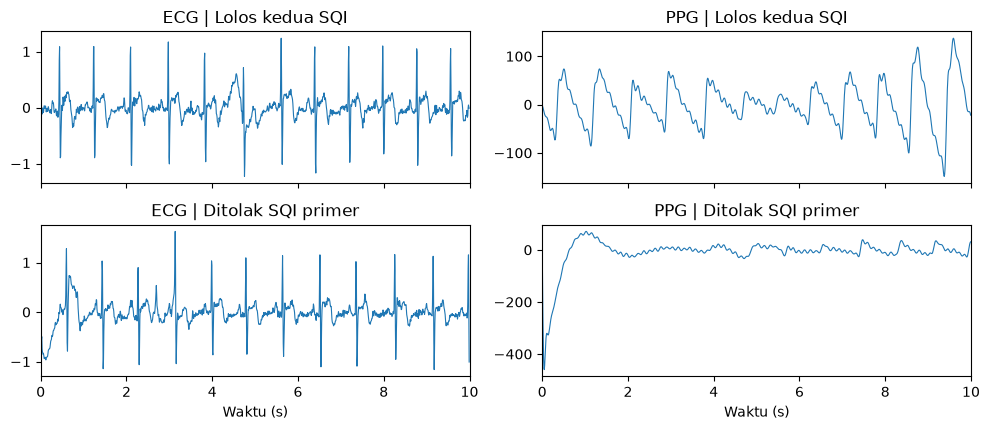

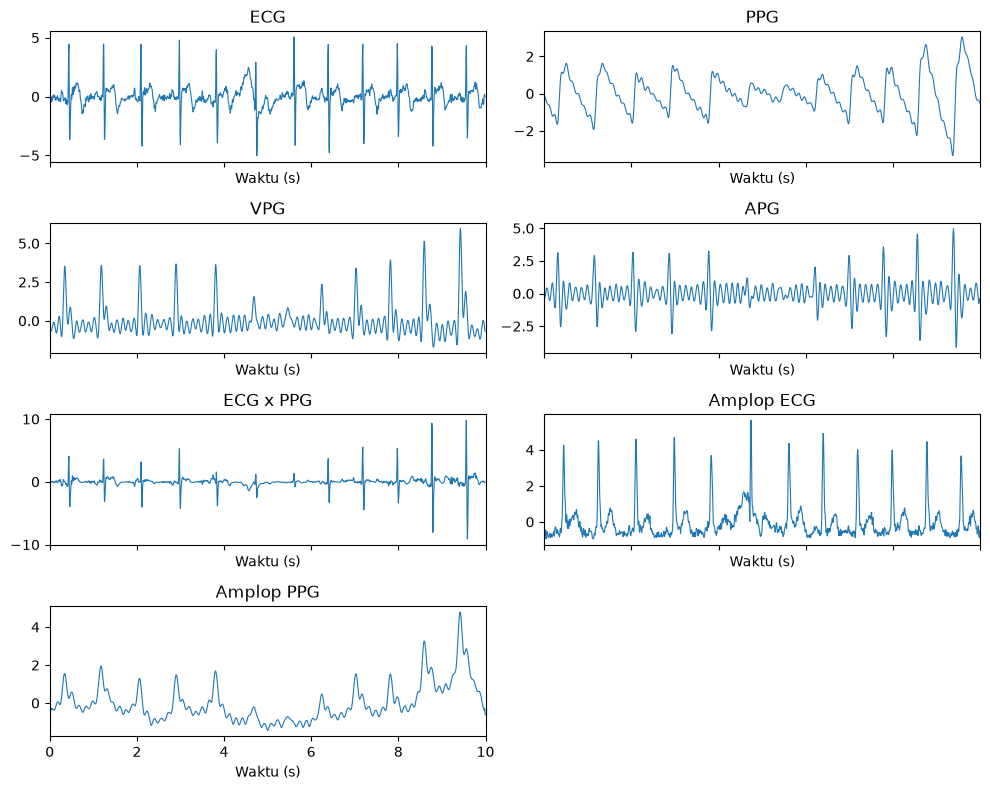

In [15]:
def extract_7channel_features(ecg_seg: np.ndarray, ppg_seg: np.ndarray, fs: float = 125.0) -> np.ndarray:
    """Construct 7 physiological channels for CNN-BiGRU [1250, 7]."""
    # 1. Z-score normalization
    ecg_norm = (ecg_seg - np.mean(ecg_seg)) / (np.std(ecg_seg) + 1e-8)
    ppg_norm = (ppg_seg - np.mean(ppg_seg)) / (np.std(ppg_seg) + 1e-8)

    # 2. VPG (1st derivative)
    vpg = np.gradient(ppg_norm, 1.0 / fs)
    vpg_norm = (vpg - np.mean(vpg)) / (np.std(vpg) + 1e-8)

    # 3. APG (2nd derivative)
    apg = np.gradient(vpg_norm, 1.0 / fs)
    apg_norm = (apg - np.mean(apg)) / (np.std(apg) + 1e-8)

    # 4. Temporal Cross-Interaction
    corr = ecg_norm * ppg_norm
    corr_norm = (corr - np.mean(corr)) / (np.std(corr) + 1e-8)

    # 5. Hilbert Instantaneous Amplitude Envelopes
    env_ecg = np.abs(hilbert(ecg_norm))
    env_ecg_norm = (env_ecg - np.mean(env_ecg)) / (np.std(env_ecg) + 1e-8)

    env_ppg = np.abs(hilbert(ppg_norm))
    env_ppg_norm = (env_ppg - np.mean(env_ppg)) / (np.std(env_ppg) + 1e-8)

    return np.stack([
        ecg_norm,
        ppg_norm,
        vpg_norm,
        apg_norm,
        corr_norm,
        env_ecg_norm,
        env_ppg_norm,
    ], axis=-1).astype(np.float32)

kanal_primer = [extract_7channel_features(e, p, fs_target) for e, p, *_ in segmen_primer]
status_primer_ketat = [alasan_sqi(x[:, 0], x[:, 1], fs_target) for x in kanal_primer]
pilih_primer = [i for i, status in enumerate(status_primer_ketat) if status == "Lolos"]
if not pilih_primer:
    raise ValueError("Tidak ada segmen primer yang lolos SQI ketat.")

X_primer = np.stack([kanal_primer[i] for i in pilih_primer])
sbp_primer = np.array([segmen_primer[i][2] for i in pilih_primer], dtype=np.float32)
dbp_primer = np.array([segmen_primer[i][3] for i in pilih_primer], dtype=np.float32)
grup_primer = np.array([segmen_primer[i][4] for i in pilih_primer])
assert X_primer.shape == (len(pilih_primer), 1250, 7)
assert len(X_primer) == len(sbp_primer) == len(dbp_primer) == len(grup_primer)
assert all(np.isfinite(data).all() for data in (X_primer, sbp_primer, dbp_primer))

display(pd.DataFrame({
    "Segmen": [len(segmen_primer), len(X_primer)],
    "Subjek": [len({s[4] for s in segmen_primer}), len(set(grup_primer))],
}, index=["Lolos SQI primer", "Lolos kedua SQI"]))
display(pd.Series(status_primer_ketat, name="Jendela").value_counts().to_frame())
print("Tensor primer:", X_primer.shape)

waktu = np.arange(panjang_jendela) / fs_target
contoh_lolos = segmen_primer[pilih_primer[0]][:2]
contoh_primer = [(*contoh_lolos, "Lolos kedua SQI")]
if contoh_gagal_primer is not None:
    e, p, alasan = contoh_gagal_primer
    print("Contoh ditolak:", alasan)
    contoh_primer.append((e, p, "Ditolak SQI primer"))
fig, axes = plt.subplots(len(contoh_primer), 2, squeeze=False, figsize=(10, 2.2 * len(contoh_primer)), sharex=True)
for baris, (e, p, status) in enumerate(contoh_primer):
    for kolom, (nama, sinyal) in enumerate((("ECG", e), ("PPG", p))):
        axes[baris, kolom].plot(waktu, sinyal, linewidth=0.8)
        axes[baris, kolom].set(title=f"{nama} | {status}", xlim=(0, 10))
for ax in axes[-1]:
    ax.set_xlabel("Waktu (s)")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(4, 2, figsize=(10, 8), sharex=True)
for indeks, (ax, nama) in enumerate(zip(axes.flat, nama_kanal)):
    ax.plot(waktu, X_primer[0, :, indeks], linewidth=0.8)
    ax.set(title=nama, xlabel="Waktu (s)", xlim=(0, 10))
axes[-1, -1].set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)


# Stage 7 — Transfer learning BPNet pada data primer

Gunakan checkpoint PulseDB historis dari Stage 4. Bekukan jaringan ekstraksi fitur, lalu salin dan latih ulang kedua bagian keluaran SBP dan DBP pada setiap fold. Setiap fold mulai dari checkpoint yang sama. Gunakan **GroupKFold tiga fold** berdasarkan peserta. Semua segmen satu peserta tetap berada di sisi latih atau sisi uji pada fold yang sama.

Rerata dan simpangan baku target dihitung dari bagian latih fold. Pelatihan kepala mengikuti `run_transfer_learning.py:123–173`: Adam, 25 epoch, loss Huber, loss selisih terhadap segmen acuan, dan penalti jarak dari bobot awal. Jaringan utama tetap dalam mode evaluasi.

Stage ini membutuhkan PyTorch. Kurva historis Stage 4 dan hasil transfer learning pada kohort baru mempunyai cakupan berbeda.

In [16]:
from copy import deepcopy
from importlib.util import find_spec

from sklearn.model_selection import GroupKFold

if find_spec("torch") is None:
    raise ImportError("Stage 7 memerlukan PyTorch pada kernel yang menjalankan notebook.")
import torch
from torch import nn

if not CHECKPOINT_BPNET.is_file():
    raise FileNotFoundError(f"Checkpoint BPNet tidak tersedia: {CHECKPOINT_BPNET}")
bpnet, _ = buat_bpnet()
bpnet.load_state_dict(torch.load(CHECKPOINT_BPNET, map_location="cpu", weights_only=True), strict=True)
bpnet.eval().requires_grad_(False)

@torch.no_grad()
def konteks_bpnet(model, segmen):
    x = model.stem(segmen.transpose(1, 2))
    x = model.drop1(model.pool1(model.inc1(x)))
    x = model.drop2(model.pool2(model.inc2(x)))
    x = model.drop3(model.pool3(model.inc3(x)))
    urutan, _ = model.bigru(x.transpose(1, 2))
    perhatian, _ = model.mhsa(urutan, urutan, urutan)
    x = model.ln(urutan + perhatian)
    return torch.cat([x.mean(dim=1), x.max(dim=1).values], dim=1)

input_primer = torch.from_numpy(X_primer).float()
konteks_primer = torch.cat([konteks_bpnet(bpnet, batch) for batch in input_primer.split(32)])
assert konteks_primer.shape == (len(X_primer), 256)
assert torch.isfinite(konteks_primer).all()

def prediksi_kepala(kepala, konteks):
    return torch.column_stack([head(konteks).squeeze(-1) for head in kepala])

def latih_kepala(konteks, target, grup):
    kepala = nn.ModuleList([deepcopy(bpnet.sbp_head), deepcopy(bpnet.dbp_head)])
    kepala.train().requires_grad_(True)
    parameter_awal = [p.detach().clone() for p in kepala.parameters()]
    optimizer = torch.optim.Adam(kepala.parameters(), lr=5e-4)
    huber = nn.SmoothL1Loss()
    _, pertama, kode = np.unique(grup, return_index=True, return_inverse=True)
    acuan = pertama[kode]
    for _ in range(25):
        optimizer.zero_grad()
        prediksi = prediksi_kepala(kepala, konteks)
        loss_absolut = huber(prediksi, target) * 2
        loss_selisih = huber(prediksi - prediksi[acuan], target - target[acuan]) * 2
        penalti = sum((p - awal).square().sum() for p, awal in zip(kepala.parameters(), parameter_awal))
        loss = loss_absolut + 1.5 * loss_selisih + 0.05 * penalti
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
    return kepala.eval()

torch.manual_seed(42)
target_primer = np.column_stack([sbp_primer, dbp_primer])
prediksi_oof = np.full_like(target_primer, np.nan)
fold_primer = np.zeros(len(X_primer), dtype=int)
pembagi = GroupKFold(n_splits=3)

for fold, (latih, uji) in enumerate(pembagi.split(X_primer, groups=grup_primer), start=1):
    assert set(grup_primer[latih]).isdisjoint(grup_primer[uji])
    assert not fold_primer[uji].any()
    rerata = target_primer[latih].mean(axis=0)
    simpangan = target_primer[latih].std(axis=0)
    if (simpangan <= 0).any():
        raise ValueError(f"Fold {fold}: simpangan baku target latih harus positif.")
    target_latih = torch.from_numpy((target_primer[latih] - rerata) / simpangan)
    kepala = latih_kepala(konteks_primer[latih], target_latih, grup_primer[latih])
    with torch.no_grad():
        prediksi_oof[uji] = prediksi_kepala(kepala, konteks_primer[uji]).numpy() * simpangan + rerata
    fold_primer[uji] = fold
    print(f"Fold {fold}: {len(set(grup_primer[latih]))} peserta latih, {len(set(grup_primer[uji]))} peserta uji.")

assert np.isfinite(prediksi_oof).all() and (fold_primer > 0).all()
assert all(not parameter.requires_grad for parameter in bpnet.parameters())

Fold 1: 40 peserta latih, 20 peserta uji.
Fold 2: 40 peserta latih, 20 peserta uji.
Fold 3: 40 peserta latih, 20 peserta uji.


## Evaluasi transfer learning

Setiap prediksi berasal dari fold yang menyisihkan peserta tersebut. Untuk kalibrasi satu titik, gunakan segmen pertama yang lolos dari tiap peserta sebagai acuan dan tambahkan **seluruh offset** rujukan dikurangi prediksi ke segmen selanjutnya. Keluarkan segmen acuan dari metrik kalibrasi. Peserta dengan satu segmen hanya masuk ringkasan tanpa kalibrasi seluruh segmen.

Tabel membedakan tiga kondisi: seluruh segmen tanpa kalibrasi, subset segmen yang sama sebelum kalibrasi, dan subset itu setelah kalibrasi. MAE dan bias dihitung dalam mmHg. Agregat dihitung dari seluruh prediksi out-of-fold pada kondisi yang sama.

**Batas data:** segmen dalam satu rekaman berbagi nilai rujukan SBP/DBP. Hasil dengan kalibrasi menunjukkan performa dalam protokol ini. Data ini belum menguji kemampuan mengikuti perubahan tekanan darah dengan rujukan baru antarsegmen.

In [17]:
prediksi_kalibrasi = np.full_like(prediksi_oof, np.nan)
mask_kalibrasi = np.zeros(len(X_primer), dtype=bool)
for peserta in np.unique(grup_primer):
    indeks = np.flatnonzero(grup_primer == peserta)
    if len(indeks) < 2:
        continue
    acuan, evaluasi = indeks[0], indeks[1:]
    assert (fold_primer[evaluasi] == fold_primer[acuan]).all()
    offset = target_primer[acuan] - prediksi_oof[acuan]
    prediksi_kalibrasi[evaluasi] = prediksi_oof[evaluasi] + offset
    mask_kalibrasi[evaluasi] = True
    assert not mask_kalibrasi[acuan]
assert np.isfinite(prediksi_kalibrasi[mask_kalibrasi]).all()

hasil_transfer = []
for nama_fold, pilih_fold in [
    *[(f"Fold {i}", fold_primer == i) for i in range(1, 4)],
    ("Agregat", np.ones(len(X_primer), dtype=bool)),
]:
    for kondisi, pilih, prediksi in [
        ("Tanpa kalibrasi — semua", pilih_fold, prediksi_oof),
        ("Tanpa kalibrasi — subset sama", pilih_fold & mask_kalibrasi, prediksi_oof),
        ("Kalibrasi 1 titik — subset sama", pilih_fold & mask_kalibrasi, prediksi_kalibrasi),
    ]:
        if not pilih.any():
            continue
        galat = prediksi[pilih] - target_primer[pilih]
        hasil_transfer.append({
            "Fold": nama_fold, "Kondisi": kondisi,
            "Peserta": len(set(grup_primer[pilih])), "Segmen": int(pilih.sum()),
            "MAE SBP (mmHg)": np.abs(galat[:, 0]).mean(), "MAE DBP (mmHg)": np.abs(galat[:, 1]).mean(),
            "Bias SBP (mmHg)": galat[:, 0].mean(), "Bias DBP (mmHg)": galat[:, 1].mean(),
        })

tabel_transfer_bpnet = pd.DataFrame(hasil_transfer).set_index(["Fold", "Kondisi"])
display(tabel_transfer_bpnet.round(3))

Peserta  Segmen  MAE SBP (mmHg)  \
Fold    Kondisi                                                            
Fold 1  Tanpa kalibrasi — semua               20     172          12.030   
        Tanpa kalibrasi — subset sama         15     152          12.296   
        Kalibrasi 1 titik — subset sama       15     152           5.013   
Fold 2  Tanpa kalibrasi — semua               20     172          14.797   
        Tanpa kalibrasi — subset sama         15     152          14.935   
        Kalibrasi 1 titik — subset sama       15     152           7.131   
Fold 3  Tanpa kalibrasi — semua               20     171           9.944   
        Tanpa kalibrasi — subset sama         15     151           9.760   
        Kalibrasi 1 titik — subset sama       15     151           3.461   
Agregat Tanpa kalibrasi — semua               60     515          12.262   
        Tanpa kalibrasi — subset sama         45     455          12.336   
        Kalibrasi 1 titik — subset sama       45     455           5.206   

                                         MAE DBP (mmHg)  Bias SBP (mmHg)  \
Fold    Kondisi                                                            
Fold 1  Tanpa kalibrasi — semua                   7.320           -8.564   
        Tanpa kalibrasi — subset sama             7.387           -9.471   
        Kalibrasi 1 titik — subset sama           2.279            0.674   
Fold 2  Tanpa kalibrasi — semua                   9.069            3.644   
        Tanpa kalibrasi — subset sama             9.129            3.451   
        Kalibrasi 1 titik — subset sama           2.907           -0.634   
Fold 3  Tanpa kalibrasi — semua                   6.016            4.716   
        Tanpa kalibrasi — subset sama             5.918            5.366   
        Kalibrasi 1 titik — subset sama           1.826            0.724   
Agregat Tanpa kalibrasi — semua                   7.471           -0.077   
        Tanpa kalibrasi — subset sama             7.481           -0.230   
        Kalibrasi 1 titik — subset sama           2.339            0.254   

                                         Bias DBP (mmHg)  
Fold    Kondisi                                           
Fold 1  Tanpa kalibrasi — semua                   -4.276  
        Tanpa kalibrasi — subset sama             -4.716  
        Kalibrasi 1 titik — subset sama           -0.044  
Fold 2  Tanpa kalibrasi — semua                    2.800  
        Tanpa kalibrasi — subset sama              2.664  
        Kalibrasi 1 titik — subset sama           -0.005  
Fold 3  Tanpa kalibrasi — semua                    2.115  
        Tanpa kalibrasi — subset sama              2.204  
        Kalibrasi 1 titik — subset sama           -0.123  
Agregat Tanpa kalibrasi — semua                    0.209  
        Tanpa kalibrasi — subset sama              0.046  
        Kalibrasi 1 titik — subset sama           -0.057

## Evaluasi berdasarkan kriteria grading BHS

Hitung proporsi prediksi dengan galat absolut ≤ 5, ≤ 10, dan ≤ 15 mmHg untuk SBP dan DBP. Gunakan grade tertinggi yang memenuhi **ketiga** batas sekaligus. Grade ditentukan sebelum persentase dibulatkan.

| Grade | ≤ 5 mmHg | ≤ 10 mmHg | ≤ 15 mmHg |
|---|---:|---:|---:|
| A | 60% | 85% | 95% |
| B | 50% | 75% | 90% |
| C | 40% | 65% | 85% |
| D | Di bawah syarat C | | |

Tabel memakai prediksi agregat dari tiga fold. Dua kondisi subset memakai segmen evaluasi yang sama, dengan segmen acuan dikeluarkan. Grade menggambarkan hasil eksperimen pada segmen TriaGo. Protokol klinis BHS mencakup prosedur pengukuran dan pembanding tambahan.

[Sumber: protokol BHS 1993, Tabel 3](https://bihs.org.uk/wp-content/uploads/2017/08/BHS_Protocol_Revision_J_Hypertens_1993_df.pdf)

In [18]:
batas_galat = np.array([5, 10, 15])
syarat_grade = {"A": (60, 85, 95), "B": (50, 75, 90), "C": (40, 65, 85)}

def grade_bhs(persentase):
    return next((grade for grade, batas in syarat_grade.items() if np.all(persentase >= batas)), "D")

hasil_bhs = []
for kondisi, pilih, prediksi in [
    ("Tanpa kalibrasi — semua", np.ones(len(target_primer), dtype=bool), prediksi_oof),
    ("Tanpa kalibrasi — subset sama", mask_kalibrasi, prediksi_oof),
    ("Kalibrasi 1 titik — subset sama", mask_kalibrasi, prediksi_kalibrasi),
]:
    if not pilih.any():
        print(f"{kondisi}: tidak ada segmen untuk dinilai.")
        continue
    galat_absolut = np.abs(prediksi[pilih] - target_primer[pilih])
    assert np.isfinite(galat_absolut).all()
    for tekanan, galat in zip(("SBP", "DBP"), galat_absolut.T):
        persentase = (galat[:, None] <= batas_galat).mean(axis=0) * 100
        hasil_bhs.append({
            "Kondisi": kondisi, "Tekanan": tekanan,
            "Peserta": len(set(grup_primer[pilih])), "Segmen": int(pilih.sum()),
            "≤ 5 mmHg (%)": persentase[0], "≤ 10 mmHg (%)": persentase[1],
            "≤ 15 mmHg (%)": persentase[2], "Grade BHS": grade_bhs(persentase),
        })

tabel_bhs_bpnet = pd.DataFrame(hasil_bhs).set_index(["Kondisi", "Tekanan"])
display(tabel_bhs_bpnet.round(2))

Peserta  Segmen  ≤ 5 mmHg (%)  \
Kondisi                         Tekanan                                  
Tanpa kalibrasi — semua         SBP           60     515         24.85   
                                DBP           60     515         36.70   
Tanpa kalibrasi — subset sama   SBP           45     455         23.08   
                                DBP           45     455         36.92   
Kalibrasi 1 titik — subset sama SBP           45     455         53.63   
                                DBP           45     455         91.21   

                                         ≤ 10 mmHg (%)  ≤ 15 mmHg (%)  \
Kondisi                         Tekanan                                 
Tanpa kalibrasi — semua         SBP              47.38          65.05   
                                DBP              71.65          91.84   
Tanpa kalibrasi — subset sama   SBP              46.59          65.49   
                                DBP              71.65          91.87   
Kalibrasi 1 titik — subset sama SBP              86.81          98.68   
                                DBP              98.46         100.00   

                                        Grade BHS  
Kondisi                         Tekanan            
Tanpa kalibrasi — semua         SBP             D  
                                DBP             D  
Tanpa kalibrasi — subset sama   SBP             D  
                                DBP             D  
Kalibrasi 1 titik — subset sama SBP             B  
                                DBP             A

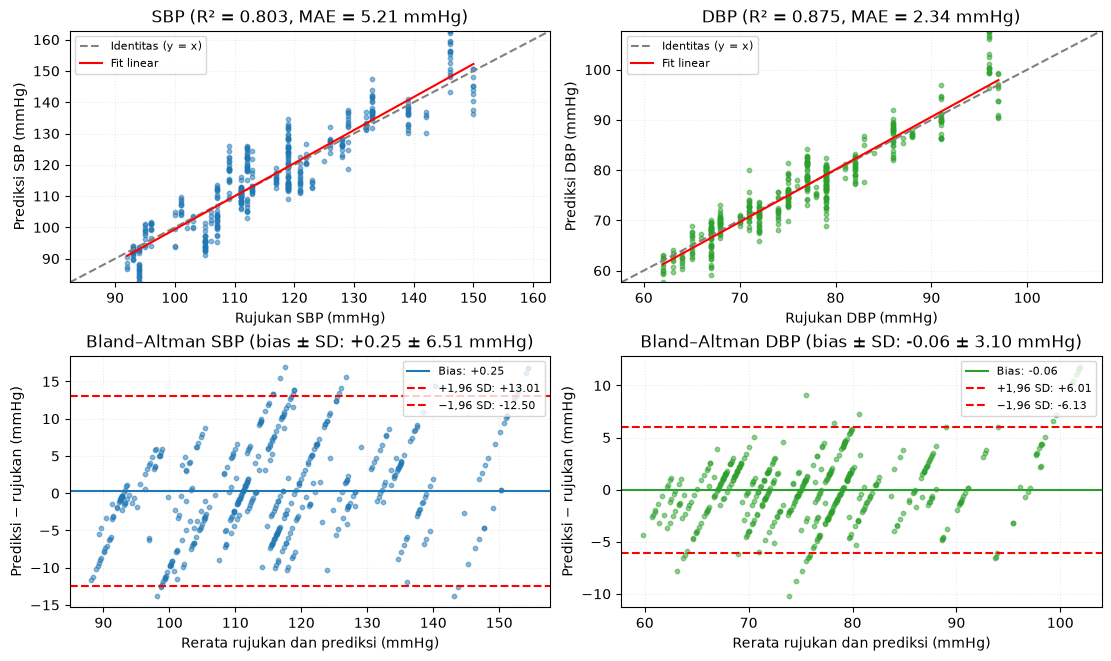

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

rujukan = target_primer[mask_kalibrasi]
prediksi = prediksi_kalibrasi[mask_kalibrasi]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), layout="constrained")

for kolom, (tekanan, warna) in enumerate(
    [("SBP", "tab:blue"), ("DBP", "tab:green")]
):
    y = rujukan[:, kolom]
    y_pred = prediksi[:, kolom]

    # Baris atas: prediksi terhadap rujukan.
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)
    kemiringan, intersep = np.polyfit(y, y_pred, 1)
    x_fit = np.array([y.min(), y.max()])
    batas = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]

    ax = axes[0, kolom]
    ax.scatter(y, y_pred, s=10, alpha=0.5, color=warna)
    ax.plot(batas, batas, "--", color="gray", label="Identitas (y = x)")
    ax.plot(x_fit, kemiringan * x_fit + intersep, color="red", label="Fit linear")
    ax.set(
        title=f"{tekanan} (R² = {r2:.3f}, MAE = {mae:.2f} mmHg)",
        xlabel=f"Rujukan {tekanan} (mmHg)",
        ylabel=f"Prediksi {tekanan} (mmHg)",
        xlim=batas,
        ylim=batas,
    )
    ax.legend(loc="upper left", fontsize=8)

    # Baris bawah: Bland–Altman.
    rata_pasangan = (y + y_pred) / 2
    galat = y_pred - y
    bias = galat.mean()
    sd = galat.std(ddof=1)
    loa_bawah = bias - 1.96 * sd
    loa_atas = bias + 1.96 * sd

    ax = axes[1, kolom]
    ax.scatter(rata_pasangan, galat, s=10, alpha=0.5, color=warna)
    ax.axhline(bias, color=warna, label=f"Bias: {bias:+.2f}")
    ax.axhline(loa_atas, color="red", linestyle="--",
               label=f"+1,96 SD: {loa_atas:+.2f}")
    ax.axhline(loa_bawah, color="red", linestyle="--",
               label=f"−1,96 SD: {loa_bawah:+.2f}")
    ax.set(
        title=f"Bland–Altman {tekanan} (bias ± SD: {bias:+.2f} ± {sd:.2f} mmHg)",
        xlabel="Rerata rujukan dan prediksi (mmHg)",
        ylabel="Prediksi − rujukan (mmHg)",
    )
    ax.legend(loc="upper right", fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.25, linestyle=":")

plt.show()